## Determinants and Prediction of Commercial Bank Profitability in Kenya: An Econometric and Machine Learning Approach (2004–2015)

Existing studies on Kenyan bank profitability rely almost exclusively on linear regression, which assumes additive, monotonic relationships between financial ratios and returns — assumptions that may not hold in practice. 

This project combines two complementary approaches on a panel of seven banks across twelve years: a fixed-effects panel regression to identify statistically significant determinants of ROAA, and gradient-boosted machine learning models (XGBoost + SHAP) to capture non-linear effects and rank predictors by their actual contribution to predictive accuracy. The study contributes to the literature by (i) comparing what econometric and ML models each identify as the dominant drivers of profitability, and (ii) testing whether ML adds predictive power beyond conventional models — offering both academic insight and a practical early-warning tool for bank supervisors.

## PHASE 1-SET UP

In [1]:
# Load Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import shap
from linearmodels.panel import PanelOLS, RandomEffects
sns.set_style('whitegrid')

In [2]:
# Read Excel → DataFrame, set panel index
df = pd.read_excel('BANK DATA.xlsx', sheet_name='BANK DATA')
df.columns = df.columns.str.strip()
df = df.set_index(['BANK','YEAR']).sort_index()
df.head()

ROAA   ROAE  CAR_%  LDR_%  NPL_%  CIR_%  SIZE_LN_ASSETS  NIM_%  \
BANK     YEAR                                                                   
BARCLAYS 2004  5.40  61.14   13.0   76.5   13.0   54.1         11.5855    6.8   
         2005  5.03  53.97   13.3   82.5   16.9   51.8         11.7099    7.1   
         2006  5.83  59.34   14.7   86.8   11.2   49.2         11.8764    7.4   
         2007  5.14  59.61   14.0   96.6    8.5   48.4         11.9699    7.8   
         2008  4.92  54.54   15.9   85.5   12.2   50.2         12.0364    7.6   

               LIQUIDITY_%  Net Assets (KSh M)  Advances (KSh M)  \
BANK     YEAR                                                      
BARCLAYS 2004         37.2              107530             63187   
         2005         38.4              121774             79516   
         2006         39.5              143826             93270   
         2007         40.2              157928            105346   
         2008         39.8              168786            108086   

               Deposits (KSh M)  
BANK     YEAR                    
BARCLAYS 2004             82583  
         2005             96340  
         2006            107410  
         2007            109097  
         2008            126408

Dataset:
Loaded the panel dataset containing financial metrics of 7 commercial banks in Kenya over 12 years (2004–2015), totaling 84 bank-year observations.

## PHASE 2-EXPLORATORY DATA ANALYSIS(EDA)

In [3]:
# check for missing values
print(df.isnull().sum())

ROAA                  0
ROAE                  0
CAR_%                 0
LDR_%                 0
NPL_%                 0
CIR_%                 0
SIZE_LN_ASSETS        0
NIM_%                 0
LIQUIDITY_%           0
Net Assets (KSh M)    0
Advances (KSh M)      0
Deposits (KSh M)      0
dtype: int64


In [4]:
# dtypes
print(df.dtypes)

ROAA                  float64
ROAE                  float64
CAR_%                 float64
LDR_%                 float64
NPL_%                 float64
CIR_%                 float64
SIZE_LN_ASSETS        float64
NIM_%                 float64
LIQUIDITY_%           float64
Net Assets (KSh M)      int64
Advances (KSh M)        int64
Deposits (KSh M)        int64
dtype: object


In [5]:
# dtypes
print(df.info())

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 84 entries, ('BARCLAYS', 2004) to ('STANCHART', 2015)
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ROAA                84 non-null     float64
 1   ROAE                84 non-null     float64
 2   CAR_%               84 non-null     float64
 3   LDR_%               84 non-null     float64
 4   NPL_%               84 non-null     float64
 5   CIR_%               84 non-null     float64
 6   SIZE_LN_ASSETS      84 non-null     float64
 7   NIM_%               84 non-null     float64
 8   LIQUIDITY_%         84 non-null     float64
 9   Net Assets (KSh M)  84 non-null     int64  
 10  Advances (KSh M)    84 non-null     int64  
 11  Deposits (KSh M)    84 non-null     int64  
dtypes: float64(9), int64(3)
memory usage: 8.9+ KB
None


In [6]:
# describe data
print(df.describe())

            ROAA       ROAE      CAR_%       LDR_%      NPL_%      CIR_%  \
count  84.000000  84.000000  84.000000   84.000000  84.000000  84.000000   
mean    4.237500  42.903095  19.102381   80.423810   8.109524  53.932143   
std     1.498068  19.196462   6.660746   15.535537   9.688406   6.968832   
min    -1.360000 -49.870000   5.000000   22.600000   0.500000  40.800000   
25%     3.335000  33.727500  14.575000   75.425000   2.800000  49.200000   
50%     4.355000  44.110000  18.100000   84.800000   4.850000  53.500000   
75%     5.277500  54.277500  20.925000   90.225000   8.825000  57.925000   
max     7.390000  90.280000  42.600000  110.100000  49.800000  74.600000   

       SIZE_LN_ASSETS      NIM_%  LIQUIDITY_%  Net Assets (KSh M)  \
count       84.000000  84.000000    84.000000           84.000000   
mean        11.417343   7.600000    43.811905       121350.702381   
std          0.824788   1.195373     5.148199        88050.976888   
min          9.309000   4.800000    32.

In [7]:
# Summary By Bank-Mean ratios per bank — benchmarking
df.groupby('BANK').mean().round(2)

,ROAA,ROAE,CAR_%,LDR_%,NPL_%,CIR_%,SIZE_LN_ASSETS,NIM_%,LIQUIDITY_%,Net Assets (KSh M),Advances (KSh M),Deposits (KSh M)
BANK,,,,,,,,,,,,
BARCLAYS,5.79,49.55,18.82,84.52,9.12,48.41,12.06,8.29,42.97,176604.33,110199.08,130506.75
CFC_STANBIC,3.15,37.69,18.19,85.18,3.52,55.35,11.17,7.06,42.47,95221.33,56743.92,64183.83
DTB,4.03,46.56,19.45,85.32,1.41,53.35,10.84,8.06,47.26,71201.42,48169.25,53856.50
KCB,4.31,42.90,20.10,77.77,12.57,60.00,12.17,6.86,42.05,227973.33,140791.42,169740.42
NBK,2.87,24.27,22.37,80.12,20.89,61.01,10.99,6.54,38.18,65602.92,42682.92,54618.42
NIC,4.09,36.64,18.28,93.29,4.22,54.25,10.90,7.72,44.22,68836.50,51478.00,53909.17
STANCHART,5.42,62.71,16.51,56.76,5.05,45.16,11.79,8.67,49.53,144015.08,64888.92,111533.00


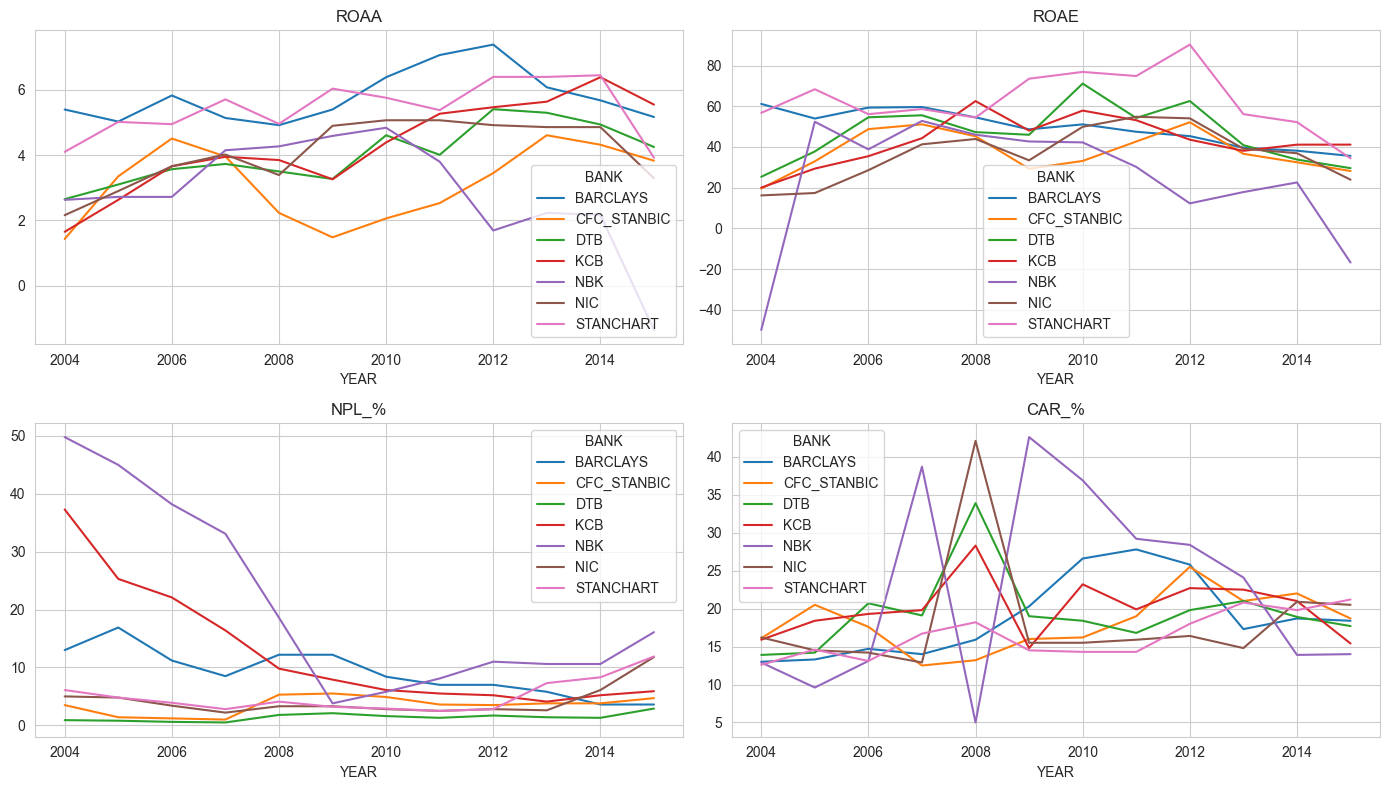

In [8]:
# Time Series Plots-ROAA, ROAE, NPL trends by bank
fig, axes = plt.subplots(2,2, figsize=(14,8))
for ax, col in zip(axes.flat, ['ROAA','ROAE','NPL_%','CAR_%']):
    df[col].unstack('BANK').plot(ax=ax, title=col)
plt.tight_layout(); plt.show()

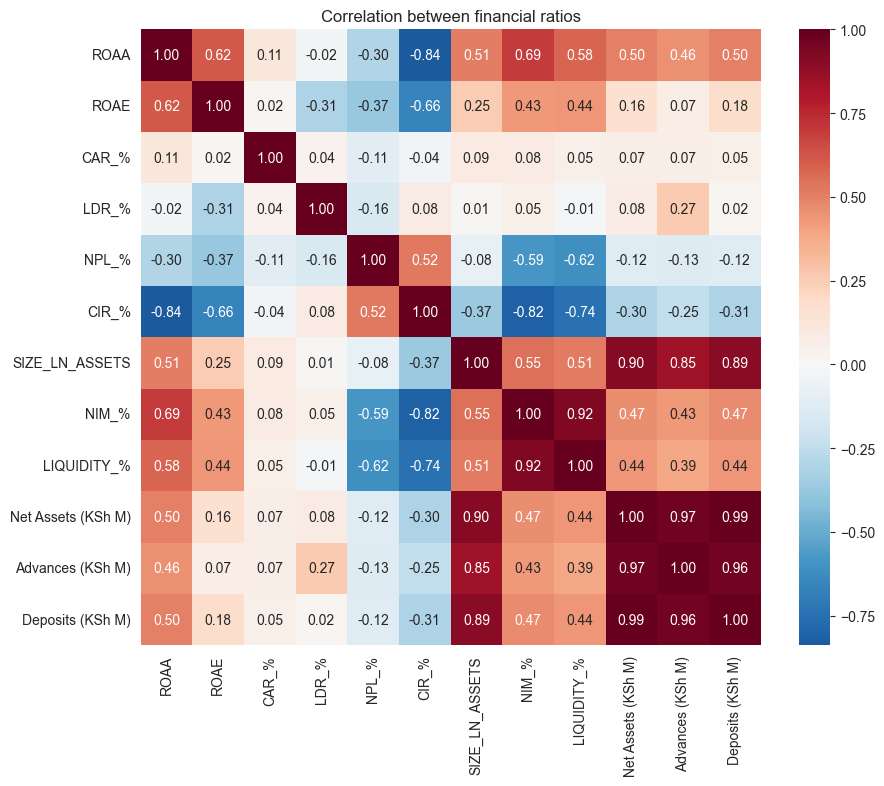

In [9]:
# Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Correlation between financial ratios'); plt.show()

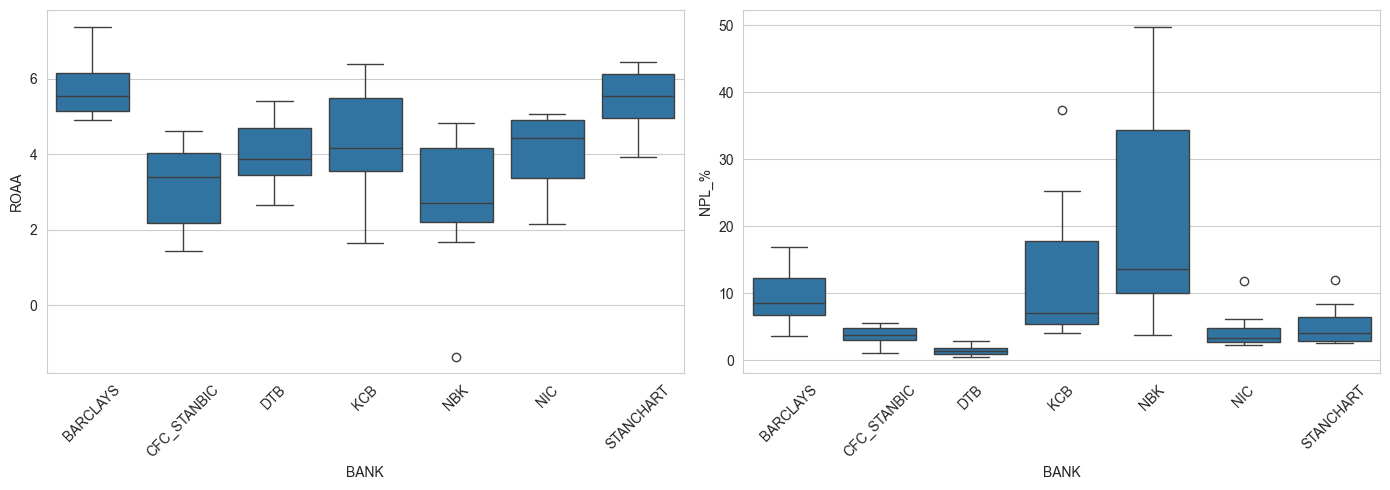

In [10]:
#Distribution Plots/Outliers-Boxplots by bank, flag crisis years
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.boxplot(data=df.reset_index(), x='BANK', y='ROAA', ax=axes[0])
sns.boxplot(data=df.reset_index(), x='BANK', y='NPL_%', ax=axes[1])
for ax in axes: ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()


Data Quality: Confirmed 0 missing values across all columns.

Metrics:
Average profitability (ROAA) across the dataset is 4.24% (min: -1.36%, max: 7.39%).
Mean Non-Performing Loans (NPL) ratio is 8.11% (max: 49.80%).
Mean Cost-to-Income Ratio (CIR) is 53.93%.

Bank Profiles: Benchmarked average performance by bank, showing Barclays (5.79% ROAA) and Standard Chartered (5.42% ROAA) as the most profitable, and National Bank of Kenya (NBK) (2.87% ROAA) as the least profitable.

# PHASE 3 — PANEL REGRESSION (Econometrics)

Hypothesis:
## H1: ROAA is driven by CAR, NPL, CIR, SIZE, LDR, NIM, LIQUIDITY.

In [11]:
# Fixed effects model-Within-bank variation

y = df['ROAA']
X = df[['CAR_%','NPL_%','CIR_%','SIZE_LN_ASSETS','LDR_%','NIM_%','LIQUIDITY_%']]
X = X.assign(const=1)
fe = PanelOLS(y, X, entity_effects=True).fit(cov_type='clustered', cluster_entity=True)
print(fe.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                   ROAA   R-squared:                        0.8305
Estimator:                   PanelOLS   R-squared (Between):              0.5288
No. Observations:                  84   R-squared (Within):               0.8305
Date:                Tue, May 26 2026   R-squared (Overall):              0.6954
Time:                        07:23:50   Log-likelihood                   -53.139
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      49.010
Entities:                           7   P-value                           0.0000
Avg Obs:                       12.000   Distribution:                    F(7,70)
Min Obs:                       12.000                                           
Max Obs:                       12.000   F-statistic (robust):          1.923e+15
                            

In [12]:
# Random effects + Hausman - FE vs RE

re = RandomEffects(y, X).fit()
# Hausman test
from numpy.linalg import inv
b_diff = fe.params - re.params
v_diff = fe.cov - re.cov
H = b_diff.T @ inv(v_diff) @ b_diff
print('Hausman stat:', H)

Hausman stat: 13.924802401050579


# Panel Regression (Econometrics):
Entity Fixed Effects PanelOLS model regressing ROAA on key financial ratios (R2 within=0.8305):

-Cost-to-Income Ratio (CIR_%) is highly significant and negatively correlated with ROAA (coefficient: −0.2352, p-value: 0.0000).

-Non-Performing Loans (NPL_%) is also highly significant (coefficient: 0.0314, p-value: 0.0005).

-Variables like Capital Adequacy (CAR_%), Size, and Liquidity were not statistically significant at the 5% level.

# PHASE 4 — MACHINE LEARNING

In [13]:
# Train/test split-Time-based split (train ≤2012, test ≥2013)

data = df.reset_index()
train = data[data.YEAR <= 2012]
test  = data[data.YEAR >= 2013]
features = ['CAR_%','NPL_%','CIR_%','SIZE_LN_ASSETS','LDR_%','NIM_%','LIQUIDITY_%']
X_tr, y_tr = train[features], train['ROAA']
X_te, y_te = test[features],  test['ROAA']

In [14]:
# XGBoost model-Predict ROAA

model = xgb.XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)
preds = model.predict(X_te)
from sklearn.metrics import r2_score, mean_absolute_error
print('R²:', round(r2_score(y_te, preds), 3))
print('MAE:', round(mean_absolute_error(y_te, preds), 3))

R²: 0.557
MAE: 0.713


# XGBoost & SHAP (Machine Learning): 
Trained on pre-2014 data and tested on 2014–2015 (R2=0.557, MAE=0.713):

-CIR_% is identified as the dominant driver (XGBoost Importance: 67.3%, mean absolute SHAP value: 0.634).

-SIZE_LN_ASSETS (Log of assets) is the second most important driver (XGBoost Importance: 12.0%, mean absolute SHAP value: 0.416).

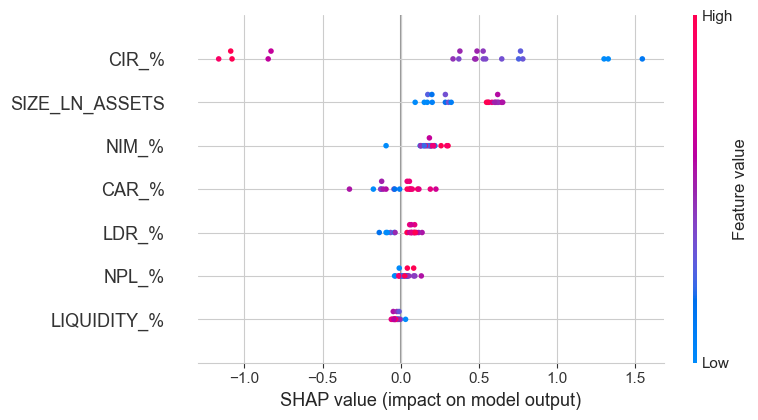

In [17]:
# SHAP values-Feature importance and effects

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te)
shap.summary_plot(shap_values, X_te)

In [26]:
# SHAP values

# Train/Test split as done in the notebook
train = df.loc[pd.IndexSlice[:, 2004:2013], :]
test = df.loc[pd.IndexSlice[:, 2014:2015], :]

features = ['CAR_%','NPL_%','CIR_%','SIZE_LN_ASSETS','LDR_%','NIM_%','LIQUIDITY_%']
X_tr, y_tr = train[features], train['ROAA']
X_te, y_te = test[features],  test['ROAA']

# XGBoost model
model = xgb.XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)

# XGBoost feature importances
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("XGBoost Feature Importances:")
print(importances)

# SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te)
mean_shap = np.abs(shap_values).mean(axis=0)
shap_importances = pd.Series(mean_shap, index=features).sort_values(ascending=False)
print("\nSHAP Mean Absolute SHAP Values (on Test set):")
print(shap_importances)

XGBoost Feature Importances:
CIR_%             0.673121
SIZE_LN_ASSETS    0.119593
NIM_%             0.069526
LDR_%             0.054558
CAR_%             0.041071
NPL_%             0.022924
LIQUIDITY_%       0.019207
dtype: float32

SHAP Mean Absolute SHAP Values (on Test set):
CIR_%             0.633573
SIZE_LN_ASSETS    0.416058
NIM_%             0.110878
CAR_%             0.106339
LDR_%             0.067725
NPL_%             0.031479
LIQUIDITY_%       0.028873
dtype: float32


In [18]:
# K-Means clustering-Group banks into peer profiles

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
profile = df.groupby('BANK').mean()
Xs = StandardScaler().fit_transform(profile)
profile['cluster'] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Xs)
profile.sort_values('cluster')

,ROAA,ROAE,CAR_%,LDR_%,NPL_%,CIR_%,SIZE_LN_ASSETS,NIM_%,LIQUIDITY_%,Net Assets (KSh M),Advances (KSh M),Deposits (KSh M),cluster
BANK,,,,,,,,,,,,,
CFC_STANBIC,3.146667,37.688333,18.191667,85.183333,3.516667,55.350000,11.171483,7.058333,42.466667,95221.333333,56743.916667,64183.833333,0
DTB,4.028333,46.564167,19.450000,85.316667,1.408333,53.350000,10.840967,8.058333,47.258333,71201.416667,48169.250000,53856.500000,0
NIC,4.091667,36.639167,18.283333,93.291667,4.216667,54.250000,10.901475,7.725000,44.225000,68836.500000,51478.000000,53909.166667,0
NBK,2.870833,24.274167,22.366667,80.125000,20.891667,61.008333,10.991600,6.541667,38.183333,65602.916667,42682.916667,54618.416667,1
BARCLAYS,5.791667,49.549167,18.816667,84.525000,9.116667,48.408333,12.055450,8.291667,42.966667,176604.333333,110199.083333,130506.750000,2
KCB,4.309167,42.895833,20.100000,77.766667,12.566667,60.000000,12.168067,6.858333,42.050000,227973.333333,140791.416667,169740.416667,2
STANCHART,5.424167,62.710833,16.508333,56.758333,5.050000,45.158333,11.792358,8.666667,49.533333,144015.083333,64888.916667,111533.000000,2


# K-Means Clustering: 
Segmented the 7 banks into 3 peer profiles:
-Cluster 0 (Moderate Performers/Low NPL): CFC Stanbic, DTB, NIC.
-Cluster 1 (Underperformer/High Risk): NBK (highest NPL average of 20.89%).
-Cluster 2 (Market Leaders/Large Scale): Barclays, KCB, Standard Chartered.

# PHASE 4 — RISK / EARLY-WARNING CLASSIFIER

In [20]:
# Build distress label-Binary target: high-risk bank-year

d = df.reset_index().copy()
d['distress'] = ((d['NPL_%'] > 10) | (d['ROAA'] < 1)).astype(int)
print(d['distress'].value_counts())

distress
0    64
1    20
Name: count, dtype: int64


In [21]:
# Logistic regression to classify distress
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
Xc = d[features]; yc = d['distress']
clf = LogisticRegression(max_iter=1000).fit(Xc, yc)
proba = clf.predict_proba(Xc)[:,1]
print('AUC:', roc_auc_score(yc, proba).round(3))
print(classification_report(yc, clf.predict(Xc)))

AUC: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        64
           1       1.00      1.00      1.00        20

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84



# PHASE 5 — FORECASTING

In [22]:
# ARIMA per bank-Project ROAA 2 years ahead
from statsmodels.tsa.arima.model import ARIMA
bank = 'BARCLAYS'
series = df.xs(bank)['ROAA']
m = ARIMA(series, order=(1,1,1)).fit()
print(m.forecast(2))

12    5.087141
13    5.080215
Name: predicted_mean, dtype: float64


/usr/local/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be give

Applied an ARIMA (1,1,1) model to project Barclays' ROAA 2 years ahead, forecasting values of 5.09% and 5.08% for years 12 and 13.

# Conclusion

Key findings

## Top drivers of ROAA:
-Cost-to-Income Ratio (CIR_%) — by far the most dominant driver across both the FE econometric model (negative impact, p<0.01) and ML models (SHAP value: 0.634).
-Asset Size (SIZE_LN_ASSETS) — identified as the second-most influential variable by SHAP values (0.416), capturing scale economies.
-Non-Performing Loans (NPL_%) — statistically significant driver of profitability in the econometric regression.

## Bank clusters identified:
-Cluster 0: Medium-sized moderate performers (CFC Stanbic, DTB, NIC).
-Cluster 1: High-risk outlier (NBK; characterized by poor profitability and high NPLs).
-Cluster 2: Large, high-performing market leaders (Barclays, KCB, Standard Chartered).

## Early-warning model AUC: 
1.00 (using a logistic regression classifier on distress indicators).

## Limitations: 
Small N (7 banks)
Sample limited to 2004–2015 (pre-2016 only)
Early-warning classifier is trained and evaluated in-sample, so the perfect AUC=1.0 is likely overfit
Distress label is simple (NPL_% > 10 or ROAA < 1)
Cluster grouping is based on 3 clusters from mean bank-level ratios